In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import os

In [6]:
BASE_DIR = Path.cwd().resolve().parent
DATA_PATH = BASE_DIR / "data"
PROCESSED_PATH = DATA_PATH / "processed"

In [7]:
df_pobreza = pd.read_parquet(path=PROCESSED_PATH / "data_pobreza.parquet")

## 1. Gráfico Vulnerabilidad por año

<Figure size 1000x800 with 0 Axes>

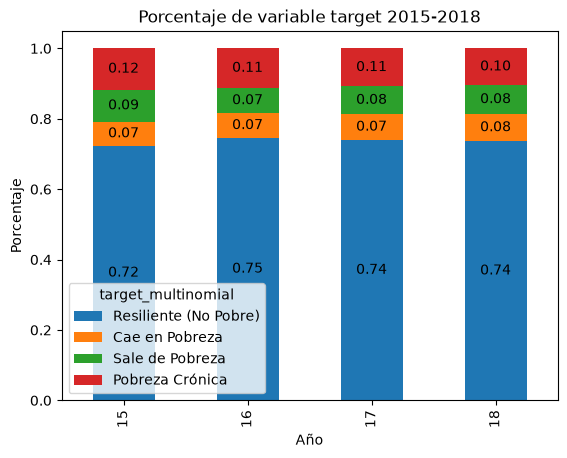

In [26]:
result_pct = pd.crosstab(df_pobreza["year"],df_pobreza["target_multinomial"],normalize="index")

diccionario_nombres = {
    0.0: "Resiliente (No Pobre)",
    1.0: "Cae en Pobreza",
    2.0: "Sale de Pobreza",
    3.0: "Pobreza Crónica"
}
result_pct = result_pct.rename(columns=diccionario_nombres)

plt.figure(figsize=(10,8))


ax = result_pct.plot(kind = "bar", stacked=True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="center")



plt.title("Porcentaje de variable target 2015-2018")
plt.ylabel("Porcentaje")
plt.xlabel("Año")
plt.show()

In [27]:
df_pobreza.columns

Index(['numpanh', 'year', 'p101', 'hogar', 'p110', 'conglome', 'vivienda',
       'gashog2d', 'inghog2d', 'linea', 'pobreza', 'n_miembros', 'n_ocupados',
       'sexo_jefe', 'edad_jefe', 'pobreza_bin', 'pobreza_futura',
       'target_multinomial'],
      dtype='object')

<Figure size 1000x800 with 0 Axes>

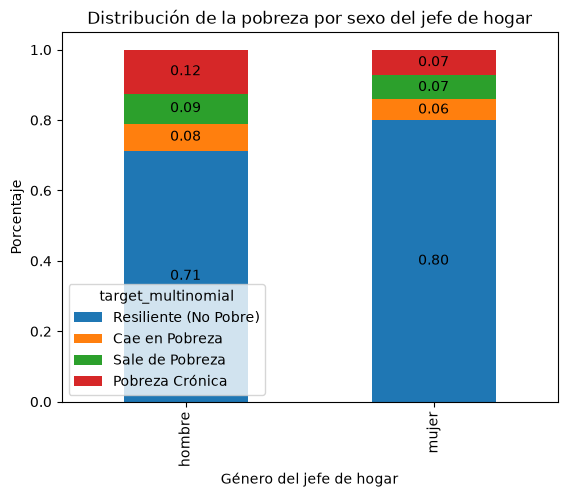

In [34]:
result_sex = pd.crosstab(df_pobreza["sexo_jefe"],df_pobreza["target_multinomial"],normalize="index")
diccionario_nombres = {
    0.0: "Resiliente (No Pobre)",
    1.0: "Cae en Pobreza",
    2.0: "Sale de Pobreza",
    3.0: "Pobreza Crónica"
}
result_sex = result_sex.rename(columns=diccionario_nombres)

plt.figure(figsize=(10,8))
ax = result_sex.plot(kind="bar", stacked=True)

for container in ax.containers:
    ax.bar_label(container,label_type="center",fmt="%.2f")
plt.title("Distribución de la pobreza por sexo del jefe de hogar")
plt.ylabel("Porcentaje")
plt.xlabel("Género del jefe de hogar")
plt.show()

<Figure size 1000x800 with 0 Axes>

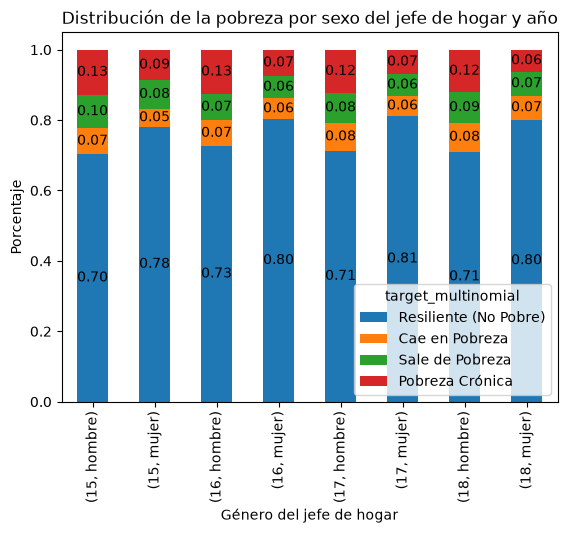

In [35]:
result_sex_anio = pd.crosstab([df_pobreza["year"], df_pobreza["sexo_jefe"]],df_pobreza["target_multinomial"],normalize="index")

diccionario_nombres = {
    0.0: "Resiliente (No Pobre)",
    1.0: "Cae en Pobreza",
    2.0: "Sale de Pobreza",
    3.0: "Pobreza Crónica"
}
result_sex_anio = result_sex_anio.rename(columns=diccionario_nombres)
plt.figure(figsize=(10,8))
ax = result_sex_anio.plot(kind="bar", stacked=True)

for container in ax.containers:
    ax.bar_label(container,label_type="center",fmt="%.2f")
plt.title("Distribución de la pobreza por sexo del jefe de hogar y año")
plt.ylabel("Porcentaje")
plt.xlabel("Género del jefe de hogar")
plt.show()

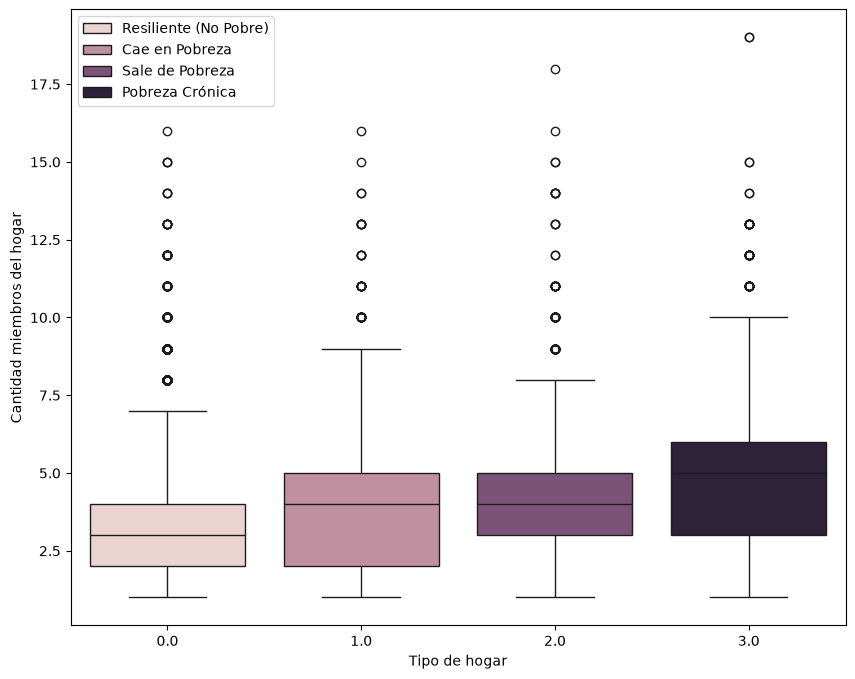

In [39]:
plt.figure(figsize=(10,8))

sns.boxplot(data = df_pobreza, x = "target_multinomial", y = "n_miembros",hue="target_multinomial")

plt.xlabel("Tipo de hogar")
plt.ylabel("Cantidad miembros del hogar")
plt.legend(["Resiliente (No Pobre)","Cae en Pobreza","Sale de Pobreza","Pobreza Crónica"])
plt.show()

<Figure size 1200x800 with 0 Axes>

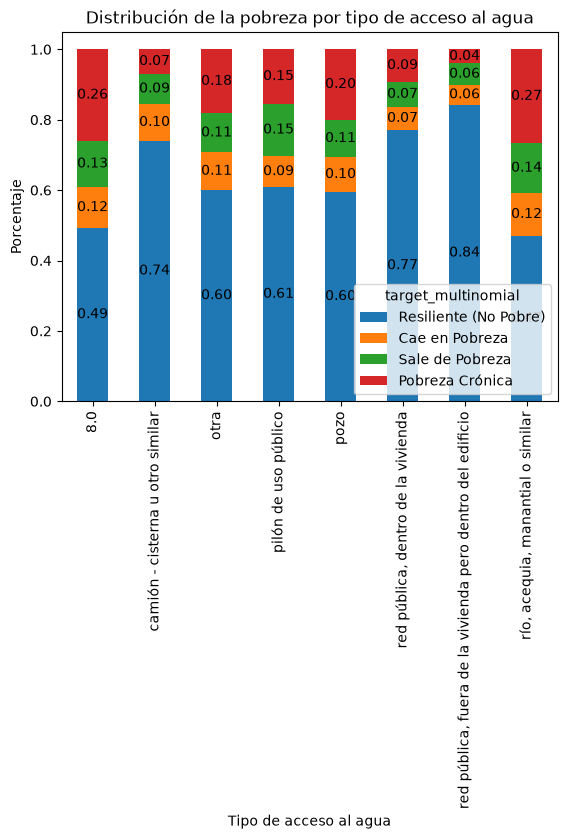

In [48]:
result_agua = pd.crosstab(df_pobreza["p110"], df_pobreza["target_multinomial"],normalize="index")

diccionario_nombres = {
    0.0: "Resiliente (No Pobre)",
    1.0: "Cae en Pobreza",
    2.0: "Sale de Pobreza",
    3.0: "Pobreza Crónica"
}
result_agua = result_agua.rename(columns=diccionario_nombres)
plt.figure(figsize=(12,8))
ax = result_agua.plot(kind="bar", stacked=True)

for container in ax.containers:
    ax.bar_label(container,label_type="center",fmt="%.2f")
plt.title("Distribución de la pobreza por tipo de acceso al agua")
plt.ylabel("Porcentaje")
plt.xlabel("Tipo de acceso al agua")
plt.xticks(rotation=90)
plt.show()

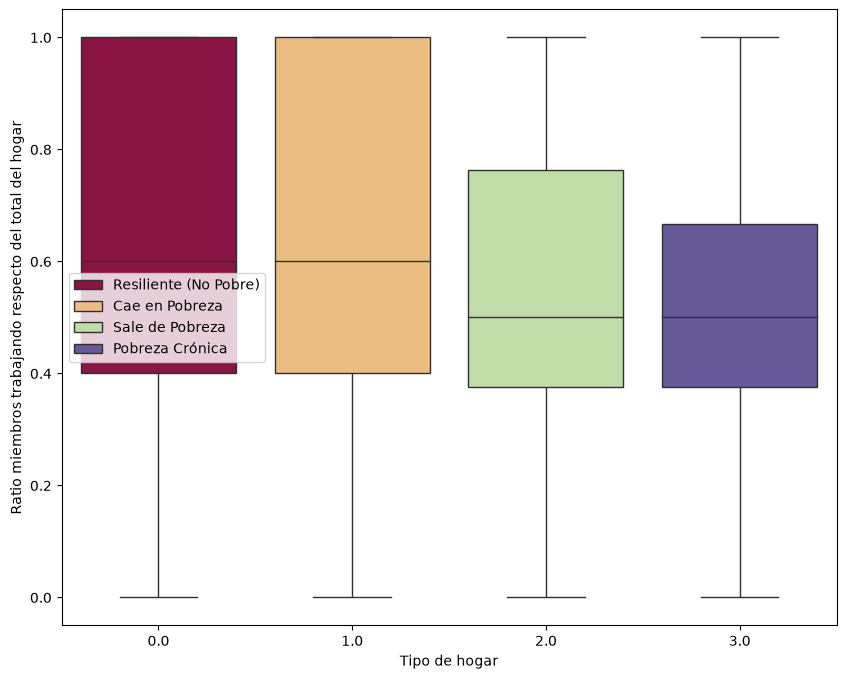

In [50]:
df_ratio = df_pobreza.copy()
df_ratio["ratio_dependencia"] = df_ratio["n_ocupados"] / df_ratio["n_miembros"]

plt.figure(figsize=(10,8))
sns.boxplot(data=df_ratio,x = "target_multinomial", y = "ratio_dependencia", hue = "target_multinomial", palette="Spectral")
plt.xlabel("Tipo de hogar")
plt.ylabel("Ratio miembros trabajando respecto del total del hogar")
plt.legend(["Resiliente (No Pobre)","Cae en Pobreza","Sale de Pobreza","Pobreza Crónica"])
plt.show()

In [51]:
# 1. Importas la función estadística
from scipy.stats import chi2_contingency

# 2. Creas una tabla de contingencia pura (OJO: SIN normalize, necesitamos contar personas reales, no porcentajes)
tabla_frecuencias = pd.crosstab(df_pobreza["p110"], df_pobreza["target_multinomial"])

# 3. Le pasas la tabla a la función
chi2, p_value, grados_libertad, tabla_esperada = chi2_contingency(tabla_frecuencias)

# 4. Imprimes el p-value
print(f"El p-value de la prueba es: {p_value}")

El p-value de la prueba es: 0.0


In [52]:
from scipy.stats import kruskal

# Separamos la variable continua (ratio) para cada uno de los 4 grupos categóricos
grupo_0 = df_ratio[df_pobreza["target_multinomial"] == 0.0]["ratio_dependencia"].dropna()
grupo_1 = df_ratio[df_pobreza["target_multinomial"] == 1.0]["ratio_dependencia"].dropna()
grupo_2 = df_ratio[df_pobreza["target_multinomial"] == 2.0]["ratio_dependencia"].dropna()
grupo_3 = df_ratio[df_pobreza["target_multinomial"] == 3.0]["ratio_dependencia"].dropna()

# Ejecutamos la prueba de Kruskal-Wallis
stat, p_value = kruskal(grupo_0, grupo_1, grupo_2, grupo_3)

print(f"Estadístico H: {stat:.4f}")
print(f"P-value: {p_value}")

if p_value < 0.05:
    print("Rechazamos la Hipótesis Nula: El ratio de dependencia ES diferente entre los grupos de pobreza.")
else:
    print("No podemos rechazar la Hipótesis Nula: No hay diferencia estadística.")

Estadístico H: 348.7278
P-value: 2.812797049913682e-75
Rechazamos la Hipótesis Nula: El ratio de dependencia ES diferente entre los grupos de pobreza.
